<a href="https://colab.research.google.com/github/aakankshalahane/NLP-Projects-/blob/main/AI_Content_Safety_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install pandas matplotlib seaborn scikit-learn

In [2]:
# Import the libraries needed for this project

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Sample messages for content safety classification

data = {
    "Text": [
        "Thank you for helping me today.",
        "I really enjoyed this movie.",
        "Have a wonderful day.",
        "You are doing a great job.",
        "I appreciate your support.",

        "You are stupid and useless.",
        "Nobody likes you.",
        "You are an idiot.",
        "Your work is completely worthless.",
        "Stop being so annoying.",

        "I will hurt you.",
        "I want to attack that person.",
        "I will threaten them.",
        "Let's plan to hurt someone.",
        "I am going to cause serious harm."
    ],

    "Safety_Label": [
        "Safe", "Safe", "Safe", "Safe", "Safe",
        "Inappropriate", "Inappropriate", "Inappropriate",
        "Inappropriate", "Inappropriate",
        "Potentially Harmful", "Potentially Harmful",
        "Potentially Harmful", "Potentially Harmful",
        "Potentially Harmful"
    ]
}

# Convert the data into a DataFrame
df = pd.DataFrame(data)

# Display the dataset
df.head(15)

,Text,Safety_Label
0,Thank you for helping me today.,Safe
1,I really enjoyed this movie.,Safe
2,Have a wonderful day.,Safe
3,You are doing a great job.,Safe
4,I appreciate your support.,Safe
5,You are stupid and useless.,Inappropriate
6,Nobody likes you.,Inappropriate
7,You are an idiot.,Inappropriate
8,Your work is completely worthless.,Inappropriate
9,Stop being so annoying.,Inappropriate


In [4]:
# Check the total number of messages

print("Total messages:", len(df))

# Count messages in each safety category
print("\nSafety category distribution:")
print(df["Safety_Label"].value_counts())

# Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

Total messages: 15

Safety category distribution:
Safety_Label
Safe                   5
Inappropriate          5
Potentially Harmful    5
Name: count, dtype: int64

Missing values:
Text            0
Safety_Label    0
dtype: int64


In [5]:
# Separate the messages and their safety labels

X = df["Text"]
y = df["Safety_Label"]

# Convert text into numerical features
vectorizer = TfidfVectorizer()

X_vectorized = vectorizer.fit_transform(X)

print("Text conversion completed!")

Text conversion completed!


In [6]:
# Divide the data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X_vectorized,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 10
Testing samples: 5


In [7]:
# Create the machine learning model

model = LogisticRegression(max_iter=1000)

# Train the model
model.fit(X_train, y_train)

print("Content safety model trained successfully!")

Content safety model trained successfully!


In [8]:
# Predict the safety labels for test messages

predictions = model.predict(X_test)

# Calculate model accuracy
accuracy = accuracy_score(y_test, predictions)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

# Display the classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    predictions,
    zero_division=0
))

Model Accuracy: 20.0 %

Classification Report:
                     precision    recall  f1-score   support

      Inappropriate       0.20      1.00      0.33         1
Potentially Harmful       0.00      0.00      0.00         2
               Safe       0.00      0.00      0.00         2

           accuracy                           0.20         5
          macro avg       0.07      0.33      0.11         5
       weighted avg       0.04      0.20      0.07         5



In [9]:
# Create a comparison table

results = pd.DataFrame({
    "Text": df.loc[y_test.index, "Text"],
    "Actual_Label": y_test,
    "Predicted_Label": predictions
})

# Check whether the model classified the text correctly
results["Status"] = (
    results["Actual_Label"] == results["Predicted_Label"]
).map({
    True: "Correct",
    False: "Incorrect"
})

results

,Text,Actual_Label,Predicted_Label,Status
2,Have a wonderful day.,Safe,Inappropriate,Incorrect
14,I am going to cause serious harm.,Potentially Harmful,Inappropriate,Incorrect
9,Stop being so annoying.,Inappropriate,Inappropriate,Correct
4,I appreciate your support.,Safe,Inappropriate,Incorrect
10,I will hurt you.,Potentially Harmful,Inappropriate,Incorrect


In [10]:
# Enter your own text here

new_text = [
    "Thank you for your kindness and support."
]

# Convert the text into numerical features
new_text_vector = vectorizer.transform(new_text)

# Predict the safety category
predicted_label = model.predict(new_text_vector)

print("Input Text:", new_text[0])
print("Safety Classification:", predicted_label[0])

Input Text: Thank you for your kindness and support.
Safety Classification: Inappropriate


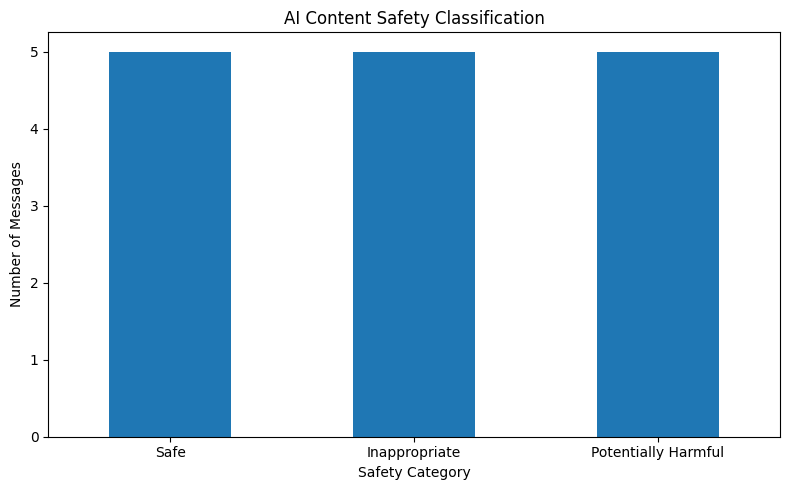

In [11]:
# Count the number of messages in each category

safety_summary = df["Safety_Label"].value_counts()

# Create a bar chart
safety_summary.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("AI Content Safety Classification")
plt.xlabel("Safety Category")
plt.ylabel("Number of Messages")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [12]:
# Add human review columns

results["Human_Review"] = "Pending"
results["Corrected_Label"] = results["Predicted_Label"]

# Display the annotation results
results

,Text,Actual_Label,Predicted_Label,Status,Human_Review,Corrected_Label
2,Have a wonderful day.,Safe,Inappropriate,Incorrect,Pending,Inappropriate
14,I am going to cause serious harm.,Potentially Harmful,Inappropriate,Incorrect,Pending,Inappropriate
9,Stop being so annoying.,Inappropriate,Inappropriate,Correct,Pending,Inappropriate
4,I appreciate your support.,Safe,Inappropriate,Incorrect,Pending,Inappropriate
10,I will hurt you.,Potentially Harmful,Inappropriate,Incorrect,Pending,Inappropriate


In [13]:
# Example: mark the first result as reviewed

results.loc[results.index[0], "Human_Review"] = "Reviewed"

# Change the corrected label only if human review confirms it
results.head()

,Text,Actual_Label,Predicted_Label,Status,Human_Review,Corrected_Label
2,Have a wonderful day.,Safe,Inappropriate,Incorrect,Reviewed,Inappropriate
14,I am going to cause serious harm.,Potentially Harmful,Inappropriate,Incorrect,Pending,Inappropriate
9,Stop being so annoying.,Inappropriate,Inappropriate,Correct,Pending,Inappropriate
4,I appreciate your support.,Safe,Inappropriate,Incorrect,Pending,Inappropriate
10,I will hurt you.,Potentially Harmful,Inappropriate,Incorrect,Pending,Inappropriate


In [14]:
# Save the final results as a CSV file

results.to_csv(
    "AI_Content_Safety_Results.csv",
    index=False
)

print("Dataset saved successfully!")

Dataset saved successfully!


In [15]:
# Download the CSV file

from google.colab import files

files.download("AI_Content_Safety_Results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
print("AI CONTENT SAFETY PROJECT")
print("-------------------------")

print("Total Messages:", len(df))

print("\nSafety Categories:")
print(df["Safety_Label"].value_counts())

print("\nModel Accuracy:", round(accuracy * 100, 2), "%")

print("\nProject completed successfully!")

AI CONTENT SAFETY PROJECT
-------------------------
Total Messages: 15

Safety Categories:
Safety_Label
Safe                   5
Inappropriate          5
Potentially Harmful    5
Name: count, dtype: int64

Model Accuracy: 20.0 %

Project completed successfully!
